# 17 k-Means และ Agglomerative Clustering
ไม่ใช้ label ตอนจัดกลุ่ม ใช้แค่ตอนดูว่ากลุ่มไหนผิดนัดเยอะ

- k-Means: เริ่มด้วย k-means++ จัดแต่ละคนเข้าศูนย์กลางที่ใกล้สุด ย้ายศูนย์กลางไปที่ค่าเฉลี่ย ทำซ้ำจนนิ่ง
- Agglomerative: เริ่มจากทุกคนเป็นกลุ่มของตัวเอง แล้วรวม 2 กลุ่มที่ใกล้สุดไปเรื่อย ๆ (ใช้ตัวอย่าง 2,000 แถว เพราะต้องสร้างตาราง n × n)

โค้ด: `Model/Classification/KMeanandAgglomerative.py`  
ผลลัพธ์: `Results/Classification/17_KMeans_Agglomerative/`

## 1. เตรียมข้อมูล

In [1]:
import os
import sys

sys.path.insert(0, os.path.abspath(os.path.join("..", "..", "Model", "Common")))

import numpy as np
import pandas as pd
from project import SEED, Outputs, classification_data
import time
import plots
from KMeanandAgglomerative import AgglomerativeScratch, KMeansScratch, adjusted_rand_index, silhouette_score

out = Outputs("Classification", "17_KMeans_Agglomerative")
d = classification_data()
print(
    f"train {d.X_tr.shape} | validation {d.X_va.shape} | test {d.X_te.shape} | "
    f"{len(d.feature_cols)} features | {d.y.mean():.1%} defaulters"
)

train (5746, 27) | validation (1916, 27) | test (1916, 27) | 27 features | 16.0% defaulters


## 2. เทรนโมเดล

In [2]:
curve = KMeansScratch(random_state=SEED).fit_k_curve(
    d.X_tr, k_values=(2, 3, 4, 5, 6, 8, 10), feature_names=d.feature_cols
)
K = int(curve["k"][int(np.argmax(curve["silhouette"]))])
km = KMeansScratch(n_clusters=K, random_state=SEED).fit(d.X_tr, feature_names=d.feature_cols)

sample = np.random.RandomState(SEED).choice(len(d.X_tr), 2000, replace=False)
Xs, ys = d.X_tr[sample], d.y_tr[sample]
agg_rows = []
for link in ("ward", "complete", "average", "single"):
    t0 = time.time()
    ag = AgglomerativeScratch(n_clusters=K, linkage=link).fit(Xs, feature_names=d.feature_cols)
    agg_rows.append(
        {
            "linkage": link,
            "silhouette": silhouette_score(ag._z(Xs), ag.labels_, random_state=SEED),
            "ARI": adjusted_rand_index(ys, ag.labels_),
            "cluster_sizes": ", ".join(str(int(n)) for n in np.bincount(ag.labels_)),
            "fit_seconds": round(time.time() - t0, 2),
        }
    )

## 3. ผลลัพธ์

 k     inertia  silhouette
 2 122768.7794      0.1332
 3 111308.5563      0.1301
 4 105203.0860      0.1400
 5 100482.6997      0.1473
 6  96081.9887      0.1527
 8  88035.7360      0.1220
10  80079.9967      0.1379

chosen k = 6 (highest silhouette 0.1527); agreement with the real defaulters (ARI, 0 = none): 0.0230

 cluster    n  default_rate  vs_overall
       0 1963         0.093       0.575
       1 2257         0.174       1.078
       2  237         0.215       1.335
       3  248         0.097       0.601
       4  723         0.315       1.957
       5  318         0.154       0.956

 linkage  silhouette     ARI               cluster_sizes  fit_seconds
    ward      0.1239  0.0349 239, 632, 809, 99, 112, 109         9.22
complete      0.1433  0.0977   241, 1570, 85, 27, 50, 27        11.11
 average      0.2207  0.0296       1947, 24, 2, 24, 1, 2         8.05
  single      0.2199 -0.0048         1994, 2, 1, 1, 1, 1        10.07


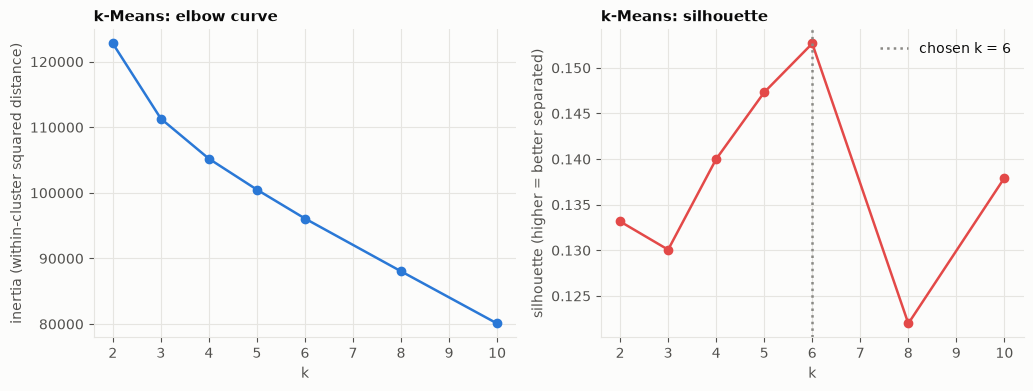

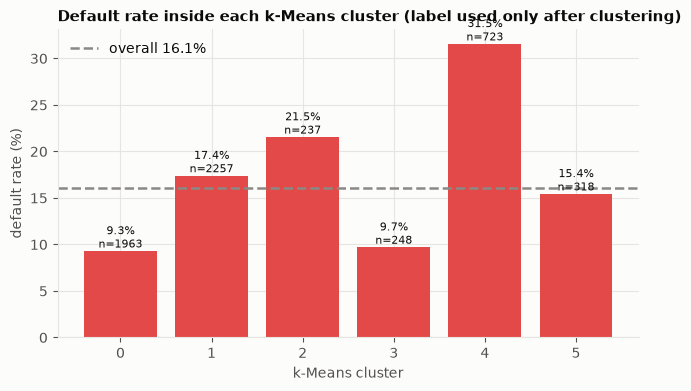

In [3]:
kc = pd.DataFrame(curve)
kc.to_csv(out.table("kmeans_k_curve.csv"), index=False)
print(kc.round(4).to_string(index=False))
print(
    f"\nchosen k = {K} (highest silhouette {max(curve['silhouette']):.4f}); "
    f"agreement with the real defaulters (ARI, 0 = none): {adjusted_rand_index(d.y_tr, km.labels_):.4f}"
)

base = d.y_tr.mean()
prof = pd.DataFrame(
    [
        {"cluster": c, "n": int((km.labels_ == c).sum()), "default_rate": d.y_tr[km.labels_ == c].mean()}
        for c in range(K)
    ]
)
prof["vs_overall"] = prof["default_rate"] / base
prof.to_csv(out.table("kmeans_clusters.csv"), index=False)
print("\n" + prof.round(3).to_string(index=False))

agg = pd.DataFrame(agg_rows)
agg.to_csv(out.table("agglomerative.csv"), index=False)
print("\n" + agg.round(4).to_string(index=False))

fig, (a1, a2) = plots.plt.subplots(1, 2, figsize=(12, 4))
a1.plot(kc["k"], kc["inertia"], "o-", color=plots.BLUE)
a1.set_xlabel("k")
a1.set_ylabel("inertia (within-cluster squared distance)")
a1.set_title("k-Means: elbow curve")
a2.plot(kc["k"], kc["silhouette"], "o-", color=plots.RED)
a2.axvline(K, color=plots.NEUTRAL, linestyle=":", label=f"chosen k = {K}")
a2.set_xlabel("k")
a2.set_ylabel("silhouette (higher = better separated)")
a2.set_title("k-Means: silhouette")
a2.legend()
plots._save(fig, out.image("kmeans_k_curve.png"))

fig, ax = plots.plt.subplots(figsize=(7.5, 4))
ax.bar(prof["cluster"].astype(str), prof["default_rate"] * 100, color=plots.RED)
ax.axhline(base * 100, color=plots.NEUTRAL, linestyle="--", label=f"overall {base:.1%}")
for c, v, n in zip(prof["cluster"], prof["default_rate"] * 100, prof["n"]):
    ax.text(c, v + 0.4, f"{v:.1f}%\nn={n}", ha="center", fontsize=8)
ax.set_xlabel("k-Means cluster")
ax.set_ylabel("default rate (%)")
ax.set_title("Default rate inside each k-Means cluster (label used only after clustering)")
ax.legend()
plots._save(fig, out.image("kmeans_default_rate.png"))